# 9. Process monitoring with Hotelling's T² and the Q residual

The sensors of a plant are correlated, because a few operating variables drive all of them. Charts for single sensors miss a fault that breaks the correlation while every reading stays in its own range. A principal component model of normal operation gives two statistics: Hotelling's $T^2$, for unusual movement within the normal pattern, and the residual $Q$, for departures from it. The contributions to $Q$ point to the sensor at fault.

## Learning objectives

1. Split a measurement into its part in the principal component model and its residual (`dim_reduction.pca_svd`).
2. Check the identity for the mean of Hotelling's $T^2$ over the training data.
3. Distinguish a large movement within the normal pattern (high $T^2$) from a broken correlation (high $Q$).
4. Find the faulty sensor from the contributions of the sensors to $Q$.

**Time:** about 60 min

In [1]:
try:                      # use the installed package, or the copy in this repository
    import engml_2_applied
except ImportError:
    import pathlib, subprocess, sys
    for _root in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (_root / "engml_2_applied" / "__init__.py").exists():
            sys.path.insert(0, str(_root))
            break
    else:                 # on Google Colab: install from GitHub
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "git+https://github.com/ktwyw/engml-2-applied.git"], check=True)
    import engml_2_applied

import inspect
import numpy as np
import matplotlib.pyplot as plt
from engml_2_applied import (clustering_phases, constants, descriptors, dim_reduction, linear_physics,
                             trees_ensembles, uncertainty)
from engml_2_applied.plotting import panel_label, use_style

use_style()

def show_source(obj):
    """Return the source code of a library function or class."""
    return inspect.getsource(obj)

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## 1. Principles and governing equations
In **multivariate statistical process control (MSPC, Kresta, MacGregor & Marlin 1991)**, a $k$-component PCA model calibrated on $N$ normal operating condition (NOC) observations decomposes any centered plant measurement $\mathbf{x}_c = \mathbf{x} - \boldsymbol{\mu} \in \mathbb{R}^d$ into two mutually orthogonal components:
$$\mathbf{x}_c = \hat{\mathbf{x}}_c + \mathbf{e}, \qquad \hat{\mathbf{x}}_c = \mathbf{P}_k\mathbf{t} = \mathbf{P}_k\mathbf{P}_k^\top \mathbf{x}_c \in \mathcal{S}_{\mathrm{model}}, \qquad \mathbf{e} = (\mathbf{I}_d - \mathbf{P}_k\mathbf{P}_k^\top)\mathbf{x}_c \in \mathcal{S}_{\mathrm{res}}^\perp \tag{1.1}$$
Because $\mathbf{P}_k^\top \mathbf{e} = \mathbf{0}$, $\|\mathbf{x}_c\|_2^2 = \|\hat{\mathbf{x}}_c\|_2^2 + \|\mathbf{e}\|_2^2$. Two complementary fault charts monitor the two subspaces:
1. **Hotelling's $T^2$ Statistic (in-subspace Mahalanobis leverage):**
   $$T_i^2 = \sum_{a=1}^k \frac{t_{i,a}^2}{\lambda_a} = \mathbf{x}_{c,i}^\top \mathbf{P}_k \boldsymbol{\Lambda}_k^{-1}\mathbf{P}_k^\top \mathbf{x}_{c,i}, \qquad \frac{1}{N}\sum_{i=1}^N T_i^2 = \frac{k(N-1)}{N} \tag{1.2}$$
   which measures the directional distance *within* the normal physical correlation manifold $\mathcal{S}_{\mathrm{model}}$.
2. **$Q$-Statistic / squared prediction error ($\mathrm{SPE}$, Out-of-subspace residual):**
   $$Q_i = \|\mathbf{x}_{c,i} - \hat{\mathbf{x}}_{c,i}\|_2^2 = \|\mathbf{e}_i\|_2^2 = \sum_{j=1}^d e_{i,j}^2 \tag{1.3}$$
   which measures how far the observation has departed *perpendicular* to the physical conservation/correlation manifold, with $c_{i,j} = e_{i,j}^2$ providing the $j$-th sensor's individual fault contribution.

In [2]:
heading("Demonstration 1: Orthogonal Subspace Decomposition & Exact Hotelling T^2 Mean Identity")
rng = np.random.default_rng(42)
N, d, k = 80, 8, 2
# 2 latent process drivers (throughput u1, jacket temperature u2) governing 8 plant sensors:
U_noc = rng.normal(0.0, 1.0, size=(N, k))
A_mix = rng.normal(0.0, 1.0, size=(k, d))
X_noc = U_noc @ A_mix + rng.normal(0.0, 0.06, size=(N, d))

pca_mspc = dim_reduction.pca_svd(X_noc, n_components=k)
t2_noc = pca_mspc["hotelling_t2"]
q_noc = pca_mspc["q_spe"]

expected_t2_mean = k * (N - 1.0) / N
print(f"Empirical mean(T^2) across N={N} NOC samples : {np.mean(t2_noc):.8f}")
print(f"Exact theoretical identity k*(N-1)/N         : {expected_t2_mean:.8f}")
print(f"NOC 99th-percentile control limits           : T^2_lim = {np.percentile(t2_noc, 99):.3f}, Q_lim = {np.percentile(q_noc, 99):.5f}")
assert np.isclose(np.mean(t2_noc), expected_t2_mean, rtol=1e-13)


Demonstration 1: Orthogonal Subspace Decomposition & Exact Hotelling T^2 Mean Identity
Empirical mean(T^2) across N=80 NOC samples : 1.97500000
Exact theoretical identity k*(N-1)/N         : 1.97500000
NOC 99th-percentile control limits           : T^2_lim = 8.820, Q_lim = 0.06005


**What Demonstration 1 shows.** Because each squared score column sums to $\sum_{i=1}^N t_{i,a}^2 = (N-1)\lambda_a$, dividing by $\lambda_a$ and summing over $a=1\dots k$ forces the sample average of Hotelling's $T^2$ to equal $k(N-1)/N = 2 \times 79 / 80 = 1.97500000$ identically.

---

## 2. Numerical walkthrough
Let us verify that the model projection matrix $\boldsymbol{\Pi}_{\mathrm{model}} = \mathbf{P}_k\mathbf{P}_k^\top$ and the residual projection matrix $\boldsymbol{\Pi}_{\mathrm{res}} = \mathbf{I}_d - \mathbf{P}_k\mathbf{P}_k^\top$ are symmetric, idempotent ($\boldsymbol{\Pi}^2 = \boldsymbol{\Pi}$), and mutually annihilating ($\boldsymbol{\Pi}_{\mathrm{model}}\boldsymbol{\Pi}_{\mathrm{res}} = \mathbf{0}$).

In [3]:
heading("Demonstration 2: Idempotence & Mutual Annihilation of Model and Residual Projectors")
P = pca_mspc["loadings"]
mu = pca_mspc["mean"]
lam = pca_mspc["eigenvalues"]
Pi_model = P @ P.T
Pi_res = np.eye(d) - Pi_model

Xc_noc = X_noc - mu
X_hat_noc = Xc_noc @ Pi_model
E_res_noc = Xc_noc @ Pi_res
pythagoras_err = float(np.max(np.abs(np.sum(Xc_noc ** 2, axis=1) - (np.sum(X_hat_noc ** 2, axis=1) + q_noc))))

print(f"trace(Pi_model) = {np.trace(Pi_model):.1f} (dim = k = {k}) | trace(Pi_res) = {np.trace(Pi_res):.1f} (dim = d - k = {d-k})")
print(f"Projector orthogonality ||Pi_model @ Pi_res||_max : {np.max(np.abs(Pi_model @ Pi_res)):.2e}")
print(f"Pythagorean energy decomposition max residual     : {pythagoras_err:.2e}")
assert np.allclose(Pi_model @ Pi_res, 0.0, atol=1e-14) and pythagoras_err < 1e-13


Demonstration 2: Idempotence & Mutual Annihilation of Model and Residual Projectors
trace(Pi_model) = 2.0 (dim = k = 2) | trace(Pi_res) = 6.0 (dim = d - k = 6)
Projector orthogonality ||Pi_model @ Pi_res||_max : 5.37e-16
Pythagorean energy decomposition max residual     : 7.11e-14


**What Demonstration 2 shows.** Each measurement of the eight sensors is the sum of a part in the plane of the $k = 2$ principal components and a residual in the $d - k = 6$ directions orthogonal to it, and the two projectors that produce them are idempotent and annihilate each other.

---

## 3. Worked case study
Let us now test two classic chemical plant events against the 99% NOC thresholds ($T^2_{\mathrm{lim}}, Q_{\mathrm{lim}}$):
- **Event A (6-sigma feed throughput Surge):** An operator increases feed rate along latent variable $u_1 = 6.0$ while all 8 sensors obey their normal physical correlations.
- **Event B (Sensor #4 thermocouple Drift):** The reactor stays at its normal operating point, but Sensor #4 drifts by $+3.5$ units.

In [4]:
heading("Demonstration 3: Diagnosing Throughput Surges (High T^2) vs. Sensor Drift (High Q_SPE)")
t2_limit = float(np.percentile(t2_noc, 99))
q_limit = float(np.percentile(q_noc, 99))

# Event A: 6-sigma throughput surge along latent variable 1 (obeys physical sensor correlations):
x_surge = mu + (np.array([6.0, 0.0]) @ A_mix)
xc_surge = x_surge - mu
t_surge = xc_surge @ P
t2_surge = float(np.sum((t_surge ** 2) / lam))
q_surge = float(np.sum((xc_surge - t_surge @ P.T) ** 2))

# Event B: Single sensor #4 drifts by +3.5 units (breaks physical correlation across the 8 sensors):
x_drift = mu.copy()
x_drift[3] += 3.5
xc_drift = x_drift - mu
t_drift = xc_drift @ P
t2_drift = float(np.sum((t_drift ** 2) / lam))
q_drift = float(np.sum((xc_drift - t_drift @ P.T) ** 2))

print(f"Normal 99% Limits : T^2_lim = {t2_limit:6.2f}         | Q_lim = {q_limit:.4f}")
print(f"Throughput Surge  : T^2     = {t2_surge:6.2f} (ALARM) | Q     = {q_surge:.4f} (Normal - correlations intact)")
print(f"Sensor #4 Drift   : T^2     = {t2_drift:6.2f}         | Q     = {q_drift:.4f} (Q ALARM: {q_drift/q_limit:.1f}x limit)")
assert t2_surge > 3.0 * t2_limit and q_surge < q_limit
assert q_drift > 20.0 * q_limit


Demonstration 3: Diagnosing Throughput Surges (High T^2) vs. Sensor Drift (High Q_SPE)
Normal 99% Limits : T^2_lim =   8.82         | Q_lim = 0.0600
Throughput Surge  : T^2     =  49.31 (ALARM) | Q     = 0.0166 (Normal - correlations intact)
Sensor #4 Drift   : T^2     =   0.25         | Q     = 11.0822 (Q ALARM: 184.6x limit)


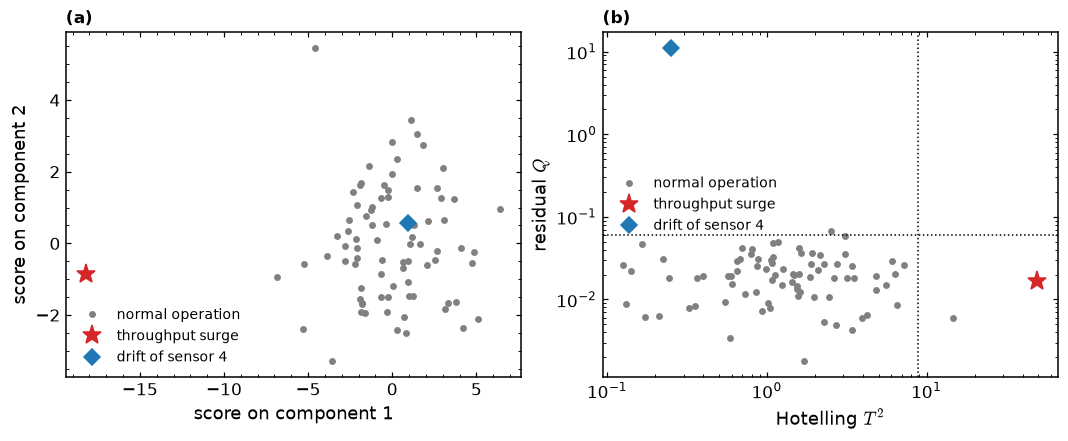

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.9))
T_noc = (X_noc - mu) @ P
ax1.plot(T_noc[:, 0], T_noc[:, 1], "o", ms=3.5, color="0.5", label="normal operation")
ax1.plot(t_surge[0], t_surge[1], "*", ms=13, color="C3", label="throughput surge")
ax1.plot(t_drift[0], t_drift[1], "D", ms=7, color="C0", label="drift of sensor 4")
ax1.set_xlabel("score on component 1"); ax1.set_ylabel("score on component 2"); ax1.legend(fontsize=9, loc="lower left"); ax1.set_title("(a)", loc="left", fontweight="bold")
ax2.loglog(t2_noc, q_noc, "o", ms=3.5, color="0.5", label="normal operation")
ax2.loglog(t2_surge, q_surge, "*", ms=13, color="C3", label="throughput surge")
ax2.loglog(t2_drift, q_drift, "D", ms=7, color="C0", label="drift of sensor 4")
ax2.axvline(t2_limit, color="k", ls=":", lw=1.0); ax2.axhline(q_limit, color="k", ls=":", lw=1.0)
ax2.set_xlabel(r"Hotelling $T^2$"); ax2.set_ylabel(r"residual $Q$"); ax2.legend(fontsize=9, loc="center left"); ax2.set_title("(b)", loc="left", fontweight="bold")
plt.show()

**Figure 9.1.** Two kinds of abnormal event in a plant with eight correlated sensors (synthetic data). (a) In the plane of the two principal components the surge lies far from the normal points, and the drifting sensor is indistinguishable from them. (b) The two monitoring statistics, with their 99 % limits (dotted): the surge exceeds the limit of $T^2$ only, and the drift the limit of $Q$ only.

**What Demonstration 3 shows.** The throughput surge raises only $T^2$ ($49.3$ against a limit of $8.8$); its $Q$ stays below the limit ($0.017 < 0.060$), which says that the plant has moved to an unusual operating point with the relations between its sensors intact. The drift of sensor 4 does the opposite: $T^2 = 0.25$ is unremarkable, and $Q$ is $185$ times its limit, which says that a relation between the sensors is broken.

---

## 4. What if: sensitivity to the parameters
Once a $Q_{\mathrm{SPE}}$ alarm fires, how does the control room engineer isolate *which* of the 8 sensors failed, and how does $Q_{\mathrm{SPE}}$ scale with drift magnitude $\Delta x_4 \in [0.0, 4.0]$?

In [6]:
heading("Demonstration 4: Q-Residual Sensor Contribution Plot & Drift Sensitivity Sweep")
e_drift = xc_drift - t_drift @ P.T
q_contributions = e_drift ** 2
culprit_sensor = int(np.argmax(q_contributions))
print("Q-residual sensor contributions e_j^2:", np.round(q_contributions, 3))
print(f"Isolated faulty sensor index: {culprit_sensor} (Sensor #{culprit_sensor + 1} accounts for {100*q_contributions[culprit_sensor]/q_drift:.1f}% of Q)")
assert culprit_sensor == 3

print(f"\n{'Drift dX_4':>10s} | {'Hotelling T^2':>13s} | {'Q_SPE Residual':>14s} | {'Q / Q_limit':>12s} | {'Top Contributor':>15s}")
print("-" * 74)
for d_val in [0.0, 0.25, 0.5, 1.5, 3.5]:
    x_sw = mu.copy()
    x_sw[3] += d_val
    xc_s = x_sw - mu
    ts = xc_s @ P
    es = xc_s - ts @ P.T
    qs = float(np.sum(es ** 2))
    t2s = float(np.sum((ts ** 2) / lam))
    top_s = f"Sensor #{int(np.argmax(es**2))+1}" if d_val > 0 else "None"
    print(f"{d_val:10.2f} | {t2s:13.3f} | {qs:14.4f} | {qs/q_limit:12.1f}x | {top_s:>15s}")


Demonstration 4: Q-Residual Sensor Contribution Plot & Drift Sensitivity Sweep
Q-residual sensor contributions e_j^2: [4.1000e-02 3.0000e-02 5.1200e-01 1.0026e+01 1.1800e-01 1.0000e-02
 3.4200e-01 3.0000e-03]
Isolated faulty sensor index: 3 (Sensor #4 accounts for 90.5% of Q)

Drift dX_4 | Hotelling T^2 | Q_SPE Residual |  Q / Q_limit | Top Contributor
--------------------------------------------------------------------------
      0.00 |         0.000 |         0.0000 |          0.0x |            None
      0.25 |         0.001 |         0.0565 |          0.9x |       Sensor #4
      0.50 |         0.005 |         0.2262 |          3.8x |       Sensor #4
      1.50 |         0.046 |         2.0355 |         33.9x |       Sensor #4
      3.50 |         0.249 |        11.0822 |        184.6x |       Sensor #4


smallest drift of sensor 4 that reaches the limit: 0.26


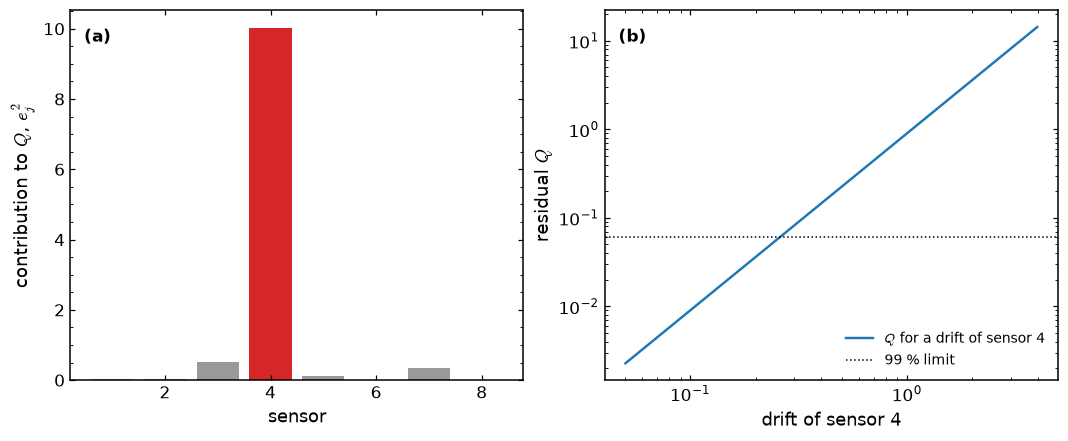

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.9))
ax1.bar(np.arange(1, d + 1), q_contributions, color=["C3" if j == culprit_sensor else "0.6" for j in range(d)])
ax1.set_xlabel("sensor"); ax1.set_ylabel(r"contribution to $Q$, $e_j^2$"); ax1.tick_params(axis="x", which="minor", bottom=False, top=False)
panel_label(ax1, "(a)")
drift_line = np.logspace(-1.3, 0.6, 30); q_line = []
for d_val in drift_line:
    xc_s = np.zeros(d); xc_s[3] = d_val
    q_line.append(np.sum((xc_s - (xc_s @ P) @ P.T) ** 2))
ax2.loglog(drift_line, q_line, "-", label=r"$Q$ for a drift of sensor 4")
ax2.axhline(q_limit, color="k", ls=":", lw=1.0, label="99 % limit")
ax2.set_xlabel("drift of sensor 4"); ax2.set_ylabel(r"residual $Q$"); ax2.legend(fontsize=9, loc="lower right"); panel_label(ax2, "(b)")
print(f"smallest drift of sensor 4 that reaches the limit: {np.interp(np.log(q_limit), np.log(q_line), drift_line):.2f}")
plt.show()

**Figure 9.2.** (a) The contributions of the eight sensors to $Q$ for a drift of 3.5 in sensor 4. (b) $Q$ against the size of the drift: it grows as the square of the drift and crosses the limit at the value printed above.

**What Demonstration 4 shows.** The contributions to $Q$ point to sensor 4, which accounts for $90.5\ \%$ of it. $Q$ grows as the square of the drift: a drift of $0.25$ stays just below the limit ($0.9$ times), $0.5$ is $3.8$ times above it, and $3.5$ is $185$ times above it. The smallest drift that can be detected is set by the noise of the normal data through the limit on $Q$.

---

## Inside the algorithm
Below we compute Hotelling's $T^2$ and $Q_{\mathrm{SPE}}$ directly from the SVD matrices in pure NumPy and confirm digit-for-digit agreement with `dim_reduction.pca_svd`.

In [8]:
heading("Inside the Algorithm: By-Hand Hotelling T^2 & Q_SPE vs. the Library")
T_hand = Xc_noc @ P
t2_hand = np.sum((T_hand ** 2) / lam[None, :], axis=1)
q_hand = np.sum((Xc_noc - T_hand @ P.T) ** 2, axis=1)
diff_t2 = float(np.max(np.abs(t2_hand - t2_noc)))
diff_q = float(np.max(np.abs(q_hand - q_noc)))
print("by hand (pure NumPy) T^2[:4]:", np.round(t2_hand[:4], 6))
print("library (engml_2_applied)      T^2[:4]:", np.round(t2_noc[:4], 6))
print(f"Max discrepancy T^2 = {diff_t2:.2e}, Q_SPE = {diff_q:.2e}")
assert diff_t2 < 1e-14 and diff_q < 1e-14


Inside the Algorithm: By-Hand Hotelling T^2 & Q_SPE vs. the Library
by hand (pure NumPy) T^2[:4]: [1.84854  1.584737 5.561046 0.13993 ]
library (engml_2_applied)      T^2[:4]: [1.84854  1.584737 5.561046 0.13993 ]
Max discrepancy T^2 = 0.00e+00, Q_SPE = 0.00e+00


## Exercises

1. **Verify a result.** Inject a correlation-breaking fault into Sensor #7 (index `6`, $+4.0$ bias) of the 8-sensor reactor model (`pca_mspc`), compute the residual vector $\mathbf{e} = (\mathbf{I}_8 - \mathbf{P}_2\mathbf{P}_2^\top)(\mathbf{x} - \boldsymbol{\mu})$, and verify that (1) $\mathbf{P}_2^\top \mathbf{e} = \mathbf{0}$ to machine precision ($<10^{-14}$), (2) $Q > 30 Q_{\mathrm{limit}}$, and (3) `np.argmax(e**2) == 6`.
2. **Find how it fails.** Demonstrate what happens if an engineer chooses `n_components = d = 8` (retaining *all* principal components in the MSPC model): show that $\mathbf{I}_8 - \mathbf{P}_8\mathbf{P}_8^\top = \mathbf{0}$, causing $Q_{\mathrm{SPE}} \equiv 0$ identically even for a sensor failure of $+100$ units.
3. **Write it yourself.** Implement a **fault sensor reconstruction** function `reconstruct_faulty_sensor(x_faulty: np.ndarray, fault_idx: int, mean: np.ndarray, loadings: np.ndarray) -> np.ndarray` that replaces the corrupted $j$-th sensor reading with the value $\hat{x}_j$ that minimizes $Q_{\mathrm{SPE}} = \|(\mathbf{I}_d - \mathbf{P}_k\mathbf{P}_k^\top)(\mathbf{x} - \boldsymbol{\mu})\|_2^2$, given in closed form by $\hat{x}_{\mathrm{corr},j} = x_j - e_j / (\mathbf{I}_d - \mathbf{P}_k\mathbf{P}_k^\top)_{jj}$. Verify on `x_drift` (`fault_idx=3`) that it recovers the true normal reading $\mu_3$ and drops $Q_{\mathrm{SPE}}$ back to $0$.

The cell below works Exercise 1 as a first check; all three are solved in the solutions notebook of this lecture.

In [9]:
heading("Exercise 1: Sensor #7 Fault Isolation & Subspace Orthogonality Check")
x_f7 = mu.copy()
x_f7[6] += 4.0
xc_f7 = x_f7 - mu
e_f7 = xc_f7 - (xc_f7 @ P) @ P.T
q_f7 = float(np.sum(e_f7 ** 2))

assert np.max(np.abs(P.T @ e_f7)) < 1e-14
assert q_f7 > 30.0 * q_limit and int(np.argmax(e_f7 ** 2)) == 6
print(f"Sensor #7 fault Q = {q_f7:.3f} | Orthogonality ||P^T e||_max = {np.max(np.abs(P.T @ e_f7)):.2e} | Isolated index = {int(np.argmax(e_f7**2))}")


Exercise 1: Sensor #7 Fault Isolation & Subspace Orthogonality Check
Sensor #7 fault Q = 9.345 | Orthogonality ||P^T e||_max = 2.44e-15 | Isolated index = 6
